# pytest

**이 노트북에서 할 일**

1. 7절 함수 `calculate_line_total()`을 모듈 파일에 저장하고, 기대값을 적은 테스트 파일을 만듭니다.
2. 새 Python에서 pytest를 실행해, 통과 표시와 요약 줄, 종료 코드를 읽습니다.
3. 7절과 같은 `int()` 빠뜨림 결함을 테스트로 찾고, 함수만 고쳐 같은 테스트를 통과시킵니다.

**준비물** — API 키 불필요. 모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

테스트 도구 pytest 9.1.1은 실습 폴더에서 `uv sync --locked`를 실행할 때 함께 설치됩니다.
1~7절과 같은 실습 폴더 `labs/part1/ch02-python`의 `.venv`를 커널로 고르고, 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

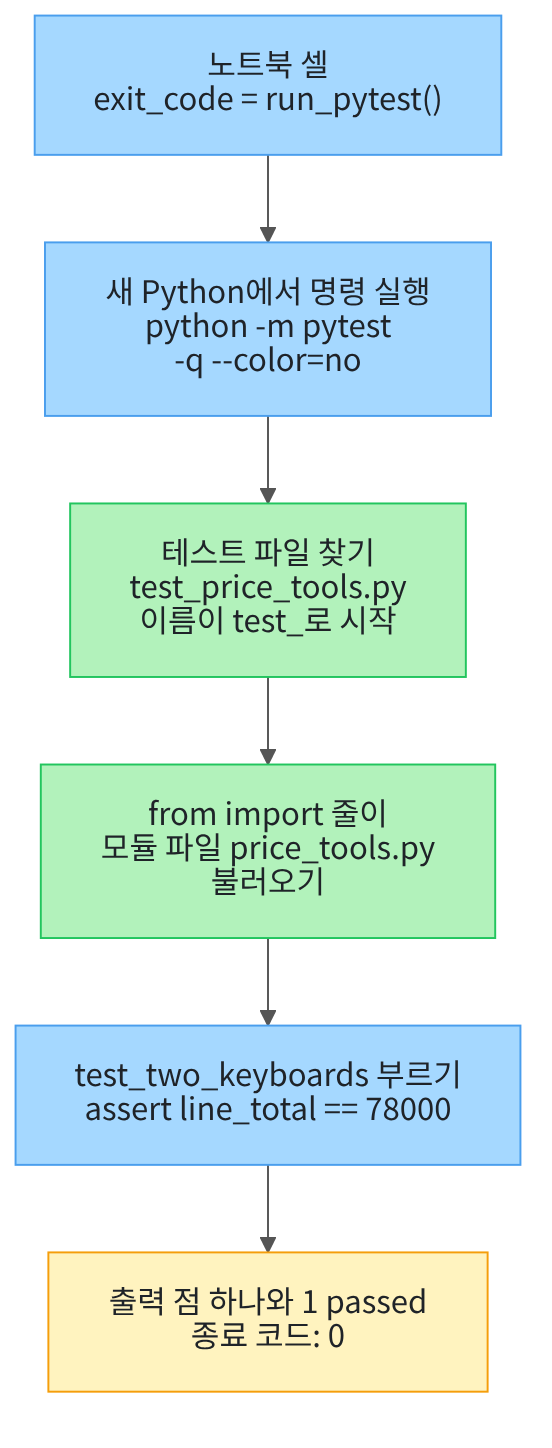

위에서 아래로 읽습니다. 파란 상자는 우리가 적은 코드, 초록 상자는 파일, 노란 상자는 출력입니다.

노트북 셀은 테스트를 직접 부르지 않습니다. 새 Python에서 실행한 pytest가 test_로 시작하는 파일과 함수를 찾아 부르고, 결과만 노트북에 전합니다.

## 1. 준비

테스트 도구 pytest는 실습 폴더의 pyproject.toml에 9.1.1 버전으로 적혀 있습니다.
첫 준비 셀은 커널에서 pytest를 불러와 버전을 출력합니다.

오류 `ModuleNotFoundError`가 나오면, Ch 1 3절처럼 커널이 실습 폴더의 `.venv`인지 확인합니다.

In [1]:
# 실습 폴더 가상환경에 설치된 pytest를 불러와 버전을 확인합니다
import pytest

# __version__은 패키지에 적어 둔 버전 글자입니다
print("pytest 버전:", pytest.__version__)

pytest 버전: 9.1.1


**결과 읽기** — pytest 버전은 `9.1.1`로, pyproject.toml에 적은 버전과 같습니다.

이 노트북은 모듈 파일과 테스트 파일을 만듭니다. 5절·7절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.

첫 두 줄은 7절에서 배운 import 문으로, 표준 라이브러리 모듈 os와 tempfile을 불러옵니다.

In [2]:
# 파일을 둘 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch02-08-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.
폴더의 경로는 컴퓨터마다 달라서 출력하지 않았습니다.

## 2. 검사할 함수를 모듈 파일에 저장하기

테스트(test)는 함수가 기대한 값을 반환하는지 확인하는 코드입니다.
먼저 검사받을 함수를 파일에 둡니다. 7절 order_tools.py처럼 정의를 글로 적어 모듈 파일 price_tools.py에 저장합니다.

함수는 7절에서 타입힌트를 적은 `calculate_line_total()`입니다. 7절 노트북에서 단가 39000, 수량 2를 넣어 78000을 얻었습니다.

실행 전에 예상합니다. 현재 작업 폴더에 파일 price_tools.py 하나가 보일 것입니다.

In [3]:
# 7절 함수 calculate_line_total()의 정의를 글로 적어 모듈 파일 price_tools.py에 저장합니다
module_text = """def calculate_line_total(unit_price: int, quantity: int = 1) -> int:
    line_total = unit_price * quantity
    return line_total
"""
with open("price_tools.py", "w", encoding="utf-8") as file:
    written_count = file.write(module_text)
file_names = os.listdir()
print("쓴 글자 수:", written_count)
print("현재 작업 폴더의 파일:", file_names)

쓴 글자 수: 130
현재 작업 폴더의 파일: ['price_tools.py']


**결과 읽기** — 쓴 글자 수는 `130`이고, 현재 작업 폴더의 파일은 `['price_tools.py']`로 예상과 같습니다.
7절 order_tools.py와 같은 방법으로 저장한 모듈 파일입니다.

## 3. 기대값을 적은 테스트 파일 만들기

테스트 함수(test function)는 검사할 함수를 부르고, 반환값이 기대값과 같은지 `assert`로 확인하는 함수입니다.
검사 줄 `assert`는 Ch 1 1절에서 처음 썼고, 1~7절 After 셀 끝에서도 썼습니다. 뒤의 비교가 참이면 지나가고, 거짓이면 그 줄에서 멈춥니다.

테스트 도구 pytest는 이름이 `test_`로 시작하는 파일을 찾습니다. 그 파일 안에서 이름이 `test_`로 시작하는 함수를 찾아 부릅니다.
그래서 파일 이름은 test_price_tools.py, 함수 이름은 test_two_keyboards로 짓습니다.

테스트 파일의 첫 줄은 7절에서 배운 from import 문입니다. 모듈 price_tools에서 함수 이름만 가져옵니다.
이 셀도 글을 저장만 하고, 테스트는 아직 실행하지 않습니다.

실행 전에 예상합니다. 현재 작업 폴더의 파일은 두 개가 될 것입니다.

In [4]:
# 단가 39000, 수량 2의 기대값 78000을 적은 테스트 파일을 저장합니다
test_text = """from price_tools import calculate_line_total


def test_two_keyboards():
    line_total = calculate_line_total(39000, 2)
    assert line_total == 78000
"""
with open("test_price_tools.py", "w", encoding="utf-8") as file:
    written_count = file.write(test_text)
# listdir()는 순서를 정하지 않고 반환하므로 sorted()로 이름 순서로 정렬합니다
file_names = sorted(os.listdir())
print("쓴 글자 수:", written_count)
print("현재 작업 폴더의 파일:", file_names)

쓴 글자 수: 152
현재 작업 폴더의 파일: ['price_tools.py', 'test_price_tools.py']


**결과 읽기** — 쓴 글자 수는 `152`이고, 현재 작업 폴더의 파일은 `['price_tools.py', 'test_price_tools.py']`로 예상과 같습니다.
테스트 파일도 모듈 파일처럼 글자로 된 .py 파일입니다.

## 4. 새 Python에서 pytest를 실행하는 함수 만들기

테스트 파일은 노트북 셀이 아니라 pytest가 불러와 실행합니다. 이 노트북은 뒤에서 price_tools.py를 고쳐 쓰고 테스트를 다시 실행합니다.

7절 주의할 점에 적은 것처럼, 모듈은 한 커널에서 처음 불러올 때 한 번만 실행됩니다.
그래서 커널 안에서 pytest를 여러 번 부르면 고친 파일이 반영되지 않을 수 있습니다. pytest 문서도 이 방법을 권하지 않습니다.
이 노트북은 pytest를 부를 때마다 새 Python을 하나 실행합니다. Ch 1 3절에서 `subprocess.run()`으로 Python을 따로 실행한 방법과 같습니다.

함수 `run_pytest()`가 실행하는 목록은 `[sys.executable, "-m", "pytest", "-q", "--color=no"]`입니다.
값 `sys.executable`은 지금 커널의 Python 파일 경로입니다. 옵션 `-m pytest`는 모듈 pytest를 실행하라는 뜻입니다.
옵션 `-q`는 출력을 짧게 줄이고, 옵션 `--color=no`는 출력 글에 색을 나타내는 기호를 넣지 않습니다.

테스트 파일이 있는 폴더의 터미널에서 `uv run python -m pytest -q --color=no`를 입력하는 것과 같은 일입니다.
노트북은 두 파일을 임시 폴더에 두었으므로, 실습 폴더에서 그대로 입력하면 찾을 테스트가 없습니다. 터미널에서는 이번에 실행하지 않았습니다.

파일 이름을 적지 않았으므로, pytest는 현재 작업 폴더에서 테스트 파일을 찾습니다.
함수는 pytest가 화면에 쓴 글(`stdout`)을 출력하고, 종료 코드(`returncode`)를 반환합니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [5]:
# 현재 작업 폴더의 테스트를 새 Python에서 pytest로 실행하고, 종료 코드를 반환합니다
import subprocess
import sys


def run_pytest() -> int:
    # 터미널에서 python -m pytest -q --color=no를 입력하는 것과 같은 명령 목록입니다
    command = [sys.executable, "-m", "pytest", "-q", "--color=no"]
    # Ch 1 3절처럼 capture_output=True, text=True로 출력을 글로 받아 둡니다
    result = subprocess.run(command, capture_output=True, text=True)
    print(result.stdout)
    return result.returncode

**결과 읽기** — 예상대로 출력이 없습니다. 함수 `run_pytest()`는 부를 때마다 새 Python에서 pytest를 실행합니다.

## 5. 테스트 실행하고 결과 읽기

함수 `run_pytest()`를 불러 테스트를 실행합니다. 테스트 도구 pytest는 test_price_tools.py를 찾아 불러옵니다. 이어서 그 파일 안의 함수 test_two_keyboards를 부릅니다.
테스트 파일의 from import 줄은 같은 폴더의 price_tools.py를 불러옵니다.

실행 전에 예상합니다. 반환값 78000이 기대값 78000과 같으므로 테스트는 통과하고, 종료 코드는 0일 것입니다.

In [6]:
# 테스트 파일 하나, 테스트 함수 하나를 pytest로 실행합니다
exit_code = run_pytest()
print("종료 코드:", exit_code)

.                                                                        [100%]
1 passed in 0.00s

종료 코드: 0


**결과 읽기** — 첫 줄의 점 `.` 하나는 테스트 함수 하나가 통과했다는 표시입니다. 줄 끝 `[100%]`는 찾은 테스트를 모두 실행했다는 진행 표시입니다. 요약 줄은 `1 passed`이고, 종료 코드는 `0`입니다.

요약 줄 끝의 시간은 실행할 때마다 달라질 수 있습니다.
pytest 문서는 종료 코드 0을 「테스트를 모두 찾았고 모두 통과함」으로 설명합니다.

## 6. 값 바꿔 보기 — 테스트 함수 하나 더하기

테스트 파일에 테스트 함수를 하나 더합니다. 4절에서 수량을 적지 않고 부르면 기본값 1이 들어가 39000이 나왔습니다.
이 기대값을 새 테스트 함수 test_one_keyboard에 적습니다. 앞의 테스트 함수와 모듈 파일은 그대로 둡니다.

실행 전에 예상합니다. 통과 표시 점이 두 개가 되고, 요약 줄은 2 passed일 것입니다.

In [7]:
# 앞 테스트는 그대로 두고, 수량을 적지 않은 테스트 함수를 더해 테스트 파일을 다시 씁니다
two_tests_text = """from price_tools import calculate_line_total


def test_two_keyboards():
    line_total = calculate_line_total(39000, 2)
    assert line_total == 78000


def test_one_keyboard():
    line_total = calculate_line_total(39000)
    assert line_total == 39000
"""
with open("test_price_tools.py", "w", encoding="utf-8") as file:
    file.write(two_tests_text)
exit_code = run_pytest()
print("종료 코드:", exit_code)

..                                                                       [100%]
2 passed in 0.00s

종료 코드: 0


**결과 읽기** — 점이 `..` 두 개로 늘었고, 요약 줄은 `2 passed`, 종료 코드는 `0`으로 예상과 같습니다.

테스트 파일에 기대값 두 개가 남았습니다. 다음에 모듈 파일을 고친 뒤에도 같은 명령 한 번으로 두 기대값을 함께 확인합니다.

## 7. Before — 단가를 꺼내는 함수에서 int()를 빠뜨림

7절 Before에서는 주문 줄 「무선 키보드,39000」을 쉼표로 나눈 단가 글자를 그대로 함수에 넣었습니다.
이번에는 단가를 꺼내는 일을 함수 `read_unit_price()`로 만들어 모듈 파일에 더합니다. 그런데 7절 Before처럼 `int()`로 바꾸는 줄을 빠뜨렸습니다.

아래 셀은 두 함수를 담은 글로 price_tools.py를 다시 씁니다. 함수 calculate_line_total은 앞과 같습니다.
새 함수의 반환값 표시는 `-> int`이지만, 7절에서 본 것처럼 타입힌트는 값을 검사하지 않습니다.

In [8]:
# 단가를 꺼내는 함수 read_unit_price()를 더해 모듈 파일을 다시 씁니다(int() 줄이 빠짐)
module_text = """def calculate_line_total(unit_price: int, quantity: int = 1) -> int:
    line_total = unit_price * quantity
    return line_total


def read_unit_price(price_line: str) -> int:
    product_name, unit_price_text = price_line.split(",")
    return unit_price_text
"""
with open("price_tools.py", "w", encoding="utf-8") as file:
    written_count = file.write(module_text)
print("쓴 글자 수:", written_count)

쓴 글자 수: 262


**결과 읽기** — 쓴 글자 수는 `262`입니다. 함수 하나만 담았던 앞의 글보다 함수 read_unit_price만큼 늘었습니다.

새 함수의 기대값을 적은 테스트 파일 test_unit_price.py를 따로 만듭니다.
주문 줄 「무선 키보드,39000」을 넣으면 정수 39000이 나와야 하므로, 기대값을 정수 39000으로 적습니다.
이 셀도 글을 저장만 합니다.

In [9]:
# 주문 줄에서 꺼낸 단가의 기대값 39000(정수)을 적은 테스트 파일을 저장합니다
unit_test_text = """from price_tools import read_unit_price


def test_read_unit_price():
    unit_price = read_unit_price("무선 키보드,39000")
    assert unit_price == 39000
"""
with open("test_unit_price.py", "w", encoding="utf-8") as file:
    written_count = file.write(unit_test_text)
print("쓴 글자 수:", written_count)

쓴 글자 수: 150


**결과 읽기** — 쓴 글자 수는 `150`입니다. 이제 테스트 파일은 두 개, 테스트 함수는 모두 세 개입니다.

파일 이름을 적지 않았으므로, pytest는 테스트 파일 두 개를 모두 찾아 실행합니다.

실행 전에 예상해 봅니다. 7절에서 타입힌트는 문자열 단가를 막지 않았습니다. 이번에는 테스트가 이 결함을 알려 줄까요?

In [10]:
# 테스트 파일 두 개, 테스트 함수 세 개를 pytest로 실행합니다
exit_code = run_pytest()
print("종료 코드:", exit_code)

..F                                                                      [100%]
=================================== FAILURES ===================================
_____________________________ test_read_unit_price _____________________________

    def test_read_unit_price():
        unit_price = read_unit_price("무선 키보드,39000")
>       assert unit_price == 39000
E       AssertionError: assert '39000' == 39000

test_unit_price.py:6: AssertionError
=========================== short test summary info ============================
FAILED test_unit_price.py::test_read_unit_price - AssertionError: assert '390...
1 failed, 2 passed in 0.01s

종료 코드: 1


**결과 읽기** — 첫 줄은 `..F`이고, 요약 줄은 `1 failed, 2 passed`, 종료 코드는 `1`입니다.
점 두 개는 test_price_tools.py의 두 테스트가 통과했다는 표시입니다. 글자 F는 실패(failed)한 테스트 하나입니다.

실패 설명에서 `>` 표시가 붙은 줄이 멈춘 줄 `assert unit_price == 39000`입니다.
바로 아래 `E` 줄 `AssertionError: assert '39000' == 39000`에는 변수 이름 대신 실제값이 들어 있습니다.
왼쪽 '39000'은 함수가 반환한 문자열, 오른쪽 39000은 테스트에 적은 정수입니다.

그 아래 `test_unit_price.py:6`은 테스트 파일의 6번째 줄에서 멈췄다는 뜻입니다.
7절에서는 틀린 금액을 출력해 보고 결함을 찾았습니다. 이번에는 기대값을 적어 둔 테스트가 실패로 알렸습니다.

## 8. After — int()로 바꾸는 줄 하나 더하기

Before 셀과 달라진 곳은 함수 `read_unit_price()` 안에 `int()` 줄 하나를 더한 것입니다. 테스트 파일 두 개와 기대값 39000은 그대로 둡니다.
테스트를 통과시키려고 기대값을 문자열 '39000'으로 바꾸면, 결함을 고친 것이 아니라 틀린 결과를 맞다고 적은 것입니다.

아래 셀은 고친 글로 price_tools.py를 다시 씁니다. 실행 전에 예상합니다. 줄 하나가 늘었으므로 쓴 글자 수는 Before보다 클 것입니다.

In [11]:
# read_unit_price()가 단가 글자를 int()로 바꿔 반환하도록 모듈 파일을 고쳐 씁니다
module_text = """def calculate_line_total(unit_price: int, quantity: int = 1) -> int:
    line_total = unit_price * quantity
    return line_total


def read_unit_price(price_line: str) -> int:
    product_name, unit_price_text = price_line.split(",")
    unit_price = int(unit_price_text)
    return unit_price
"""
with open("price_tools.py", "w", encoding="utf-8") as file:
    written_count = file.write(module_text)
print("쓴 글자 수:", written_count)

쓴 글자 수: 295


**결과 읽기** — 쓴 글자 수는 `295`로, Before의 262보다 큽니다. 모듈 파일만 고쳤고 테스트 파일은 쓰지 않았습니다.

Before 셀과 같은 함수 `run_pytest()`로 같은 테스트 파일 두 개를 다시 실행합니다.
함수는 부를 때마다 새 Python을 실행하므로, pytest는 고친 price_tools.py를 새로 불러옵니다.

실행 전에 예상합니다. 세 테스트가 모두 통과해 점 세 개와 3 passed, 종료 코드 0이 나올 것입니다.

In [12]:
# 테스트 파일은 그대로 두고, 고친 모듈 파일로 같은 테스트를 다시 실행합니다
exit_code = run_pytest()
print("종료 코드:", exit_code)
# 테스트가 하나라도 실패해 종료 코드가 0이 아니면 이 줄에서 멈춥니다
assert exit_code == 0

...                                                                      [100%]
3 passed in 0.00s

종료 코드: 0


**결과 읽기** — 첫 줄은 `...`, 요약 줄은 `3 passed`, 종료 코드는 `0`입니다. 검사 줄 `assert`에서도 멈추지 않았습니다.

Before 셀의 ..F와 비교하면 F 자리가 점으로 바뀌었습니다. 달라진 곳은 모듈 파일의 `int()` 줄 하나이고, 테스트 파일과 기대값은 그대로입니다.

이번에 확인한 입력은 「무선 키보드,39000」 한 줄입니다. 쉼표가 없는 줄이나 「삼만구천」처럼 정수로 바꿀 수 없는 단가는 테스트하지 않았습니다.

### 원리 더 알아보기 — 매개변수화

입력만 다른 테스트를 함수 하나로 적는 pytest 기능을 매개변수화(parametrization)라고 합니다. 이 셀은 수량 1·2·3을 한 함수로 검사합니다.
테스트 함수 위에 `@pytest.mark.parametrize` 줄을 적습니다. 이 줄은 아래 테스트 함수를 입력 묶음마다 한 번씩 실행하도록 등록합니다.

기호 `@`로 시작하는 줄의 뜻은 9절 데코레이터에서 배우므로, 지금은 출력만 읽습니다.
이 셀은 테스트 파일을 하나 더 만들어, 앞의 세 테스트와 함께 실행합니다.

In [13]:
# 원리 더 알아보기: 수량 1·2·3의 입력 묶음 세 개를 테스트 함수 하나에 넣어 실행합니다
quantity_test_text = """import pytest
from price_tools import calculate_line_total


@pytest.mark.parametrize("quantity, expected", [(1, 39000), (2, 78000), (3, 117000)])
def test_quantities(quantity, expected):
    line_total = calculate_line_total(39000, quantity)
    assert line_total == expected
"""
with open("test_quantities.py", "w", encoding="utf-8") as file:
    file.write(quantity_test_text)
deep_exit_code = run_pytest()
print("종료 코드:", deep_exit_code)

......                                                                   [100%]
6 passed in 0.00s

종료 코드: 0


**결과 읽기** — 점이 `......` 여섯 개이고, 요약 줄은 `6 passed`입니다.
앞의 세 테스트에, 테스트 함수 test_quantities가 입력 묶음 세 개로 세 번 실행되어 더해졌습니다.
수량 3의 기대값 117000은 7절 값 바꿔 보기에서 얻은 금액입니다.

## 정리

- 테스트 함수는 검사할 함수를 부르고 `assert`로 기대값과 비교합니다. 테스트 도구 pytest는 이름이 test_로 시작하는 파일과 함수를 찾아 부릅니다.
- 결과는 점(통과)과 F(실패), 요약 줄의 passed·failed 수, 종료 코드 0·1로 읽습니다.
- `int()` 줄을 빠뜨린 함수에서 테스트가 ..F로 실패했고, 기대값은 두고 함수만 고치자 3 passed가 되었습니다.

확장 경로(B)는 9절 데코레이터와 컨텍스트 매니저로, 기본 경로(A)는 12절 async와 await로 이어집니다.